# Journey to Zero — Predict Electricity Consumption (LSTM)

Kaggle competition: [predict-electricity-consumption](https://www.kaggle.com/competitions/predict-electricity-consumption).

We forecast hourly `consumption` for the held-out test week (25–31 Aug 2022) with a multivariate LSTM that reads the past 24 hours of weather, electricity price, and calendar features.

In [21]:
import time
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler

DEVICE = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Using device: {DEVICE}')

Using device: mps


## 1. Load competition data

In [22]:
LOCAL_DATA = Path('journey_to_zero_data')

try:
    path = Path(kagglehub.competition_download('predict-electricity-consumption'))
    print('Downloaded via kagglehub:', path)
except Exception as exc:
    print(f'kagglehub download skipped ({type(exc).__name__}: {exc})')
    path = LOCAL_DATA
    print('Using local data folder:', path.resolve())

train = pd.read_csv(path / 'train.csv')
test = pd.read_csv(path / 'test.csv')
sample = pd.read_csv(path / 'sample_submission.csv')

for df in (train, test, sample):
    df['time'] = pd.to_datetime(df['time'], utc=True).dt.tz_convert('Europe/Tallinn')

train = train.sort_values('time').reset_index(drop=True)
test = test.sort_values('time').reset_index(drop=True)

print(f'Train: {train.shape}  |  {train["time"].iloc[0]} → {train["time"].iloc[-1]}')
print(f'Test:  {test.shape}  |  {test["time"].iloc[0]} → {test["time"].iloc[-1]}')
train.head()

kagglehub download skipped (UnauthenticatedError: User is not authenticated)
Using local data folder: /Users/tomhait/git/tom.aharon-hait/python/reccurent_networks/journey_to_zero_data
Train: (8592, 13)  |  2021-09-01 00:00:00+03:00 → 2022-08-24 23:00:00+03:00
Test:  (168, 12)  |  2022-08-25 00:00:00+03:00 → 2022-08-31 23:00:00+03:00


,time,temp,dwpt,rhum,prcp,snow,wdir,wspd,wpgt,pres,coco,el_price,consumption
0,2021-09-01 00:00:00+03:00,11.2,10.3,94.0,NaN,NaN,320.0,7.2,16.7,1012.6,2.0,0.09016,0.577
1,2021-09-01 01:00:00+03:00,10.7,9.6,93.0,NaN,NaN,320.0,7.2,13.0,1012.6,2.0,0.09251,0.594
2,2021-09-01 02:00:00+03:00,9.9,9.0,94.0,NaN,NaN,320.0,7.2,13.0,1012.2,2.0,0.08890,0.685
3,2021-09-01 03:00:00+03:00,10.0,8.4,90.0,NaN,NaN,330.0,7.2,13.0,1011.9,1.0,0.08735,1.016
4,2021-09-01 04:00:00+03:00,9.0,8.1,94.0,NaN,NaN,300.0,3.6,13.0,1011.4,2.0,0.08688,0.677


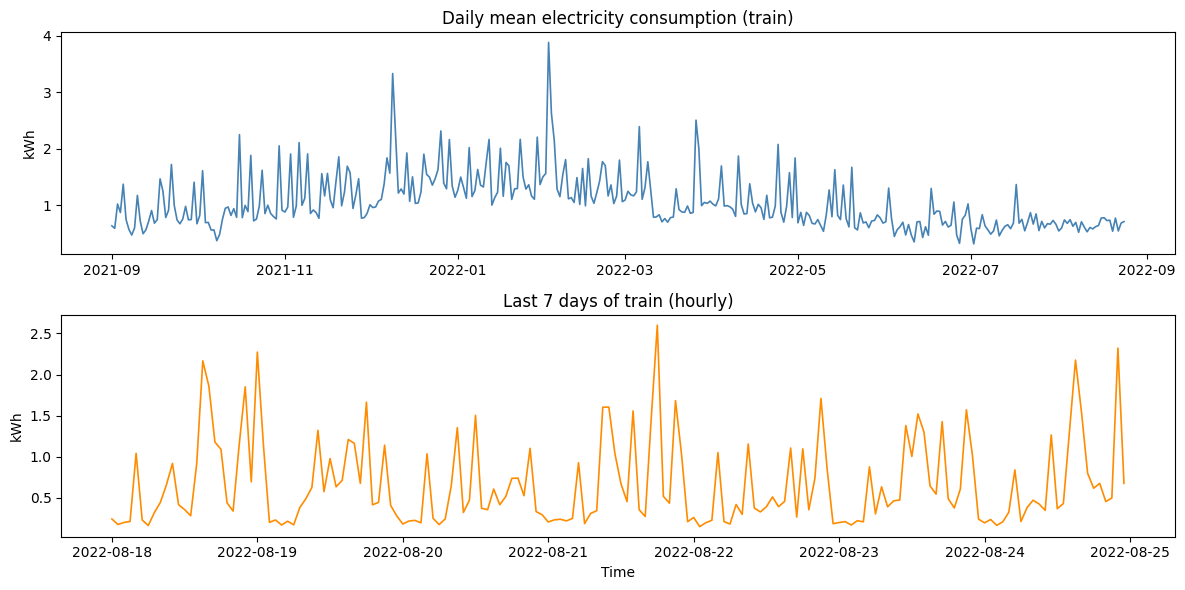

In [13]:
daily = train.set_index('time')['consumption'].resample('D').mean()

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
axes[0].plot(daily.index, daily.values, linewidth=1.2, color='steelblue')
axes[0].set_title('Daily mean electricity consumption (train)')
axes[0].set_ylabel('kWh')

week = train.set_index('time')['consumption'].iloc[-7 * 24 :]
axes[1].plot(week.index, week.values, linewidth=1.2, color='darkorange')
axes[1].set_title('Last 7 days of train (hourly)')
axes[1].set_ylabel('kWh')
axes[1].set_xlabel('Time')
plt.tight_layout()
plt.show()

## 2. Features and sequences

In [23]:
FEATURE_COLS = [
    'temp', 'dwpt', 'rhum', 'prcp', 'snow', 'wdir', 'wspd', 'wpgt', 'pres', 'coco', 'el_price',
    'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'is_weekend',
]

def add_calendar_features(df):
    out = df.copy()
    hour = out['time'].dt.hour
    dow = out['time'].dt.dayofweek
    month = out['time'].dt.month
    out['hour_sin'] = np.sin(2 * np.pi * hour / 24)
    out['hour_cos'] = np.cos(2 * np.pi * hour / 24)
    out['dow_sin'] = np.sin(2 * np.pi * dow / 7)
    out['dow_cos'] = np.cos(2 * np.pi * dow / 7)
    out['month_sin'] = np.sin(2 * np.pi * month / 12)
    out['month_cos'] = np.cos(2 * np.pi * month / 12)
    out['is_weekend'] = (dow >= 5).astype(float)
    return out

def clean_weather(df):
    out = df.copy()
    out['prcp'] = out['prcp'].fillna(0.0)
    out['snow'] = out['snow'].fillna(0.0)
    out['coco'] = out['coco'].ffill().bfill()
    return out

train_f = add_calendar_features(clean_weather(train))
test_f = add_calendar_features(clean_weather(test))

train_f['consumption'] = train_f['consumption'].interpolate(limit_direction='both')

print('Feature columns:', FEATURE_COLS)
print('Train NaNs left:', train_f[FEATURE_COLS + ['consumption']].isna().sum().sum())
print('Test NaNs left:', test_f[FEATURE_COLS].isna().sum().sum())

Feature columns: ['temp', 'dwpt', 'rhum', 'prcp', 'snow', 'wdir', 'wspd', 'wpgt', 'pres', 'coco', 'el_price', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'is_weekend']
Train NaNs left: 0
Test NaNs left: 0


In [ ]:
class ConsumptionLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size, hidden_size, num_layers,
            batch_first=True,
        )
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])


def make_sequences(features, targets, seq_len):
    X, y = [], []
    for i in range(len(features) - seq_len):
        if np.isnan(targets[i + seq_len]):
            continue
        X.append(features[i : i + seq_len])
        y.append(targets[i + seq_len])
    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)


def train_model(
    X_train,
    y_train,
    epochs=100,
    lr=1e-3,
    hidden_size=64,
    verbose=True,
    X_val=None,
    y_val=None,
):
    model = ConsumptionLSTM(
        input_size=X_train.shape[-1],
        hidden_size=hidden_size,
    ).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    X_t = torch.tensor(X_train, device=DEVICE)
    y_t = torch.tensor(y_train, device=DEVICE).unsqueeze(1)
    has_val = X_val is not None
    if has_val:
        X_v = torch.tensor(X_val, device=DEVICE)
        y_v = torch.tensor(y_val, device=DEVICE).unsqueeze(1)

    history = {'train': [], 'val': []}
    best_state = None
    best_val = float('inf')
    best_epoch = epochs
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        loss = loss_fn(model(X_t), y_t)
        opt.zero_grad()
        loss.backward()
        opt.step()
        history['train'].append(loss.item())

        if has_val:
            model.eval()
            with torch.no_grad():
                v = float(loss_fn(model(X_v), y_v))
            history['val'].append(v)
            if v < best_val:
                best_val = v
                best_epoch = epoch
                best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}

        if verbose and (epoch == 1 or epoch % 10 == 0 or epoch == epochs):
            msg = f'  epoch {epoch:3d}  train MSE: {loss.item():.6f}'
            if has_val:
                msg += f'  val MSE: {history["val"][-1]:.6f}'
            print(msg)

    if best_state is not None:
        model.load_state_dict(best_state)
        model.to(DEVICE)

    elapsed = time.time() - t0
    return model, history, elapsed, best_epoch


def predict(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X, device=DEVICE)).cpu().numpy().flatten()


def time_series_cv_best_epoch(
    features_raw,
    targets_raw,
    seq_len=24,
    n_splits=4,
    max_epochs=100,
    hidden_size=64,
    lr=1e-3,
    min_train_frac=0.5,
):
    n = len(features_raw)
    min_train = max(int(n * min_train_frac), seq_len + 24 * 60)
    remaining = n - min_train
    fold_size = remaining // n_splits

    fold_val_curves = []
    fold_norm_curves = []
    fold_best_epochs = []
    fold_stats = []

    print(f'Walk-forward CV: {n_splits} folds, max_epochs={max_epochs}')
    print(f'  min_train_rows={min_train} ({min_train / 24:.0f} days), fold_size={fold_size} ({fold_size / 24:.0f} days)')

    for fold in range(n_splits):
        train_end = min_train + fold * fold_size
        val_end = n if fold == n_splits - 1 else train_end + fold_size

        feat_scaler = StandardScaler()
        y_scaler = StandardScaler()

        tr_feat = feat_scaler.fit_transform(features_raw[:train_end])
        va_feat = feat_scaler.transform(features_raw[train_end:val_end])
        tr_y = y_scaler.fit_transform(targets_raw[:train_end].reshape(-1, 1)).flatten()
        va_y = y_scaler.transform(targets_raw[train_end:val_end].reshape(-1, 1)).flatten()

        X_tr, y_tr = make_sequences(tr_feat, tr_y, seq_len)

        feat_tv = np.vstack([tr_feat, va_feat])
        y_tv = np.concatenate([tr_y, va_y])
        X_va, y_va = [], []
        for t in range(train_end, val_end):
            if t < seq_len:
                continue
            X_va.append(feat_tv[t - seq_len : t])
            y_va.append(y_tv[t])
        X_va = np.asarray(X_va, dtype=np.float32)
        y_va = np.asarray(y_va, dtype=np.float32)

        if len(X_tr) < 10 or len(X_va) < 10:
            print(f'  fold {fold + 1}: skipped (too few sequences)')
            continue

        model, hist, _, best_ep = train_model(
            X_tr, y_tr,
            epochs=max_epochs,
            lr=lr,
            hidden_size=hidden_size,
            verbose=False,
            X_val=X_va,
            y_val=y_va,
        )

        val_curve = np.asarray(hist['val'], dtype=np.float64)
        norm_curve = val_curve / max(val_curve[0], 1e-8)

        preds_s = predict(model, X_va)
        preds = y_scaler.inverse_transform(preds_s.reshape(-1, 1)).flatten()
        true = y_scaler.inverse_transform(y_va.reshape(-1, 1)).flatten()
        mae = float(np.mean(np.abs(preds - true)))
        rmse = float(np.sqrt(np.mean((preds - true) ** 2)))

        fold_val_curves.append(val_curve)
        fold_norm_curves.append(norm_curve)
        fold_best_epochs.append(best_ep)
        fold_stats.append({
            'fold': fold + 1,
            'train_rows': train_end,
            'val_rows': val_end - train_end,
            'best_epoch': best_ep,
            'best_val_mse_scaled': float(val_curve.min()),
            'mae_kwh': mae,
            'rmse_kwh': rmse,
        })

        print(
            f'  fold {fold + 1}/{n_splits}: '
            f'train={train_end} ({train_end / 24:.0f}d), '
            f'val={val_end - train_end} ({(val_end - train_end) / 24:.0f}d), '
            f'best_epoch={best_ep}, '
            f'val_MSE_scaled={val_curve.min():.4f}, '
            f'MAE={mae:.3f} kWh, RMSE={rmse:.3f} kWh'
        )

    norm_mean = np.mean(np.stack(fold_norm_curves, axis=0), axis=0)
    epoch_from_norm_mean = int(np.argmin(norm_mean) + 1)
    epoch_from_median = int(np.median(fold_best_epochs))
    best_epoch = epoch_from_median

    print(
        f'\nEpoch from normalized-mean curve: {epoch_from_norm_mean}'
        f'\nEpoch from median of fold bests:  {epoch_from_median}'
    )

    return (
        best_epoch,
        norm_mean,
        fold_best_epochs,
        fold_val_curves,
        fold_norm_curves,
        fold_stats,
        epoch_from_norm_mean,
    )

## 3. Time-series CV → choose best epoch

Expanding-window **walk-forward** CV on train (past → future only).
Scalers are fit **inside each fold** on that fold's training slice.
We average validation MSE across folds and pick the epoch with the lowest mean val loss, then use that budget for the final model.

In [25]:
SEQ_LEN = 24
MAX_EPOCHS = 100
N_SPLITS = 5

features_raw = train_f[FEATURE_COLS].values.astype(np.float64)
targets_raw = train_f['consumption'].values.astype(np.float64)

BEST_EPOCHS, val_mean_curve, fold_best_epochs, fold_val_curves = time_series_cv_best_epoch(
    features_raw,
    targets_raw,
    seq_len=SEQ_LEN,
    n_splits=N_SPLITS,
    max_epochs=MAX_EPOCHS,
)

print(
    f'\nSelected BEST_EPOCHS = {BEST_EPOCHS}  '
    f'(fold-wise best epochs: {fold_best_epochs}, '
    f'median={int(np.median(fold_best_epochs))})'
)

Walk-forward CV: 5 folds, max_epochs=100
  min_train_rows=1227, fold_size=1473
  fold 1/5: train_rows=1227, val_rows=1473, seq_train=1203, seq_val=1473
    best epoch=59, best val MSE=1.572909
  fold 2/5: train_rows=2700, val_rows=1473, seq_train=2676, seq_val=1473
    best epoch=24, best val MSE=0.867651
  fold 3/5: train_rows=4173, val_rows=1473, seq_train=4149, seq_val=1473
    best epoch=11, best val MSE=0.717848
  fold 4/5: train_rows=5646, val_rows=1473, seq_train=5622, seq_val=1473
    best epoch=20, best val MSE=0.650928
  fold 5/5: train_rows=7119, val_rows=1473, seq_train=7095, seq_val=1473
    best epoch=15, best val MSE=0.284927

Selected BEST_EPOCHS = 15  (fold-wise best epochs: [59, 24, 11, 20, 15], median=20)


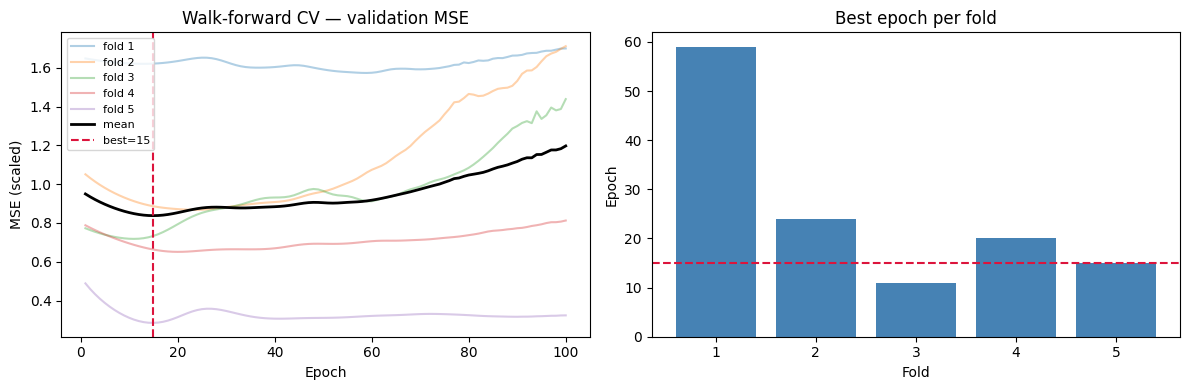

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i, curve in enumerate(fold_val_curves):
    axes[0].plot(range(1, len(curve) + 1), curve, alpha=0.35, label=f'fold {i + 1}')
axes[0].plot(range(1, len(val_mean_curve) + 1), val_mean_curve, color='black', linewidth=2, label='mean')
axes[0].axvline(BEST_EPOCHS, color='crimson', linestyle='--', label=f'best={BEST_EPOCHS}')
axes[0].set_title('Walk-forward CV — validation MSE')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE (scaled)')
axes[0].legend(fontsize=8)

axes[1].bar(range(1, len(fold_best_epochs) + 1), fold_best_epochs, color='steelblue')
axes[1].axhline(BEST_EPOCHS, color='crimson', linestyle='--')
axes[1].set_title('Best epoch per fold')
axes[1].set_xlabel('Fold')
axes[1].set_ylabel('Epoch')
plt.tight_layout()
plt.show()

## 4. Full-train model + competition submission

Retrain on **all** train sequences for `BEST_EPOCHS` chosen by time-series CV, then score the 168-hour test week.
Test immediately follows train, so early test windows reuse the end of the training feature history.

In [ ]:
feat_scaler_full = StandardScaler()
y_scaler_full = StandardScaler()

train_feats_full = feat_scaler_full.fit_transform(train_f[FEATURE_COLS].values)
test_feats_full = feat_scaler_full.transform(test_f[FEATURE_COLS].values)
train_y_full = y_scaler_full.fit_transform(train_f[['consumption']].values).flatten()

X_full, y_full = make_sequences(train_feats_full, train_y_full, SEQ_LEN)
print(f'Full train sequences: {len(X_full)}  |  epochs: {BEST_EPOCHS}')

model_full, hist_full, time_full, _ = train_model(
    X_full, y_full, epochs=BEST_EPOCHS, verbose=True
)
print(f'Full training time: {time_full:.2f}s')

In [28]:
all_feats = np.vstack([train_feats_full, test_feats_full])
n_train = len(train_feats_full)

X_test = []
for i in range(len(test_feats_full)):
    end = n_train + i
    start = end - SEQ_LEN
    X_test.append(all_feats[start:end])
X_test = np.asarray(X_test, dtype=np.float32)

preds_test_s = predict(model_full, X_test)
preds_test = y_scaler_full.inverse_transform(preds_test_s.reshape(-1, 1)).flatten()
preds_test = np.clip(preds_test, 0, None)

sample_raw = pd.read_csv(path / 'sample_submission.csv')
submission = sample_raw.copy()
submission['consumption'] = preds_test
submission_path = Path('submission.csv')
submission.to_csv(submission_path, index=False)
print(f'Wrote {submission_path.resolve()}  ({len(submission)} rows)')
submission.head()

Wrote /Users/tomhait/git/tom.aharon-hait/python/reccurent_networks/submission.csv  (168 rows)


,time,consumption
0,2022-08-25 00:00:00+03:00,0.485923
1,2022-08-25 01:00:00+03:00,0.458035
2,2022-08-25 02:00:00+03:00,0.487976
3,2022-08-25 03:00:00+03:00,0.483116
4,2022-08-25 04:00:00+03:00,0.528857


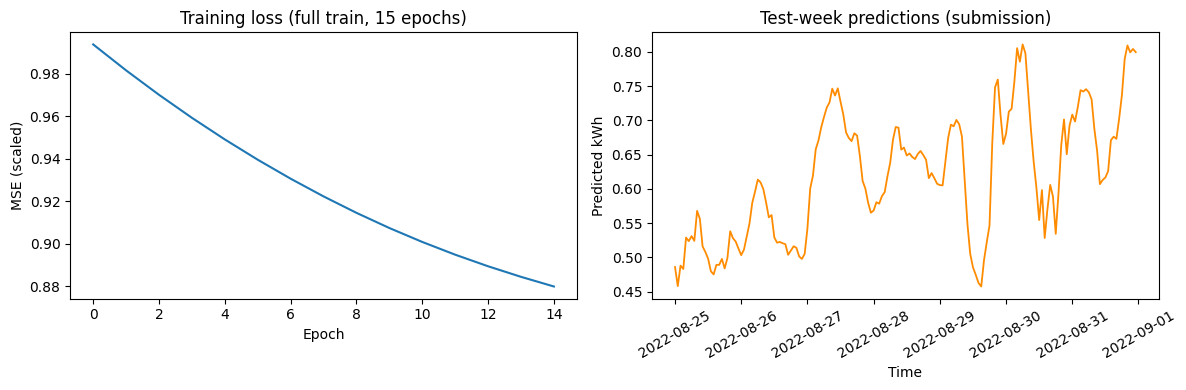

count    168.000000
mean       0.619491
std        0.091851
min        0.457496
25%        0.530455
50%        0.615690
75%        0.689507
max        0.810865
Name: consumption, dtype: float64


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_full['train'])
axes[0].set_title(f'Training loss (full train, {BEST_EPOCHS} epochs)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE (scaled)')

axes[1].plot(test_f['time'], preds_test, color='darkorange', linewidth=1.3)
axes[1].set_title('Test-week predictions (submission)')
axes[1].set_xlabel('Time')
axes[1].set_ylabel('Predicted kWh')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print(submission['consumption'].describe())

## 5. Notes

- **Target:** hourly `consumption` (kWh) for 168 test hours.
- **Model:** 1-layer LSTM (64 hidden), 24-hour look-back, weather + `el_price` + calendar features.
- **Epoch selection:** expanding-window time-series CV (5 folds); final retrain uses `BEST_EPOCHS`.
- **Submit:** upload `submission.csv` on the competition page.
- Previous Kaggle Public / Private scores (fixed 100 epochs): 0.37832 / 0.43388.